# 🌿 Notebook 01: Aquisição, Exploração e Limpeza de Dados de Biodiversidade
**Projeto Aplicado III — Ciência de Dados e Inteligência Artificial (Mackenzie)**  
**Tema:** Sistema de Recomendação de Espécies Nativas para Reflorestamento e Arborização Urbana (ODS 15)  
**Grupo:** Fernanda Pauli de Oliveira, Henrique Sarmento, Milena Dias Gouveia, Nicolly Falcão da Silva  

---

## 📌 Objetivos deste Notebook
1. **Ingestão e Coleta de Dados:** Conectar e carregar registros de três repositórios públicos oficiais:
   - **Flora e Funga do Brasil (JBRJ):** Catálogo taxonômico oficial, biomas de ocorrência nativa, formas de vida e tolerâncias ambientais.
   - **Inventário Florestal Nacional (SFB / MAPA):** Unidades amostrais em conglomerados de campo ($20 \times 20\text{ m}$), abundância viva por espécie e propriedades físico-químicas de solos.
   - **GBIF (Global Biodiversity Information Facility):** Registros georreferenciados contínuos de coletas botânicas via API (`pygbif`).
2. **Análise Exploratória de Dados (EDA):** Diagnosticar volumetria, distribuição taxonômica, riqueza de espécies por parcela, distribuição de variáveis edafoclimáticas e severidade da esparsidade matricial.
3. **Limpeza e Tratamento Especializado:**
   - Resolução taxonômica automatizada de sinonímias guiada pelo vocabulário controlado do JBRJ;
   - Subamostragem espacial (*spatial thinning*) para neutralizar viés de adensamento urbano/rodoviário do GBIF;
   - Imputação de variáveis ambientais faltantes baseada em conservadorismo filogenético (gênero/família).
4. **Exportação de Artefatos:** Gerar bases tratadas em `data/processed/` e amostras curadas em `data/sample/` para alimentar o pipeline de produção `src/data_prep.py`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de visualização
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Definição de caminhos do projeto
BASE_DIR = os.path.dirname(os.path.abspath('')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_RAW = os.path.join(BASE_DIR, 'data', 'raw')
DATA_PROC = os.path.join(BASE_DIR, 'data', 'processed')
DATA_SAMPLE = os.path.join(BASE_DIR, 'data', 'sample')

for p in [DATA_RAW, DATA_PROC, DATA_SAMPLE]:
    os.makedirs(p, exist_ok=True)

print(f"Diretório base: {BASE_DIR}")
print(f"Diretórios de dados configurados.")

Diretório base: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 3\ProjetoAplicado3
Diretórios de dados configurados.


## 1. Coleta e Ingestão de Dados das Três Fontes
Para permitir execução reprodutível, autossuficiente e robusta (sem dependência de instabilidades temporárias de download de dezenas de gigabytes em rede), estruturamos um módulo de ingestão das bases representativas das principais espécies nativas brasileiras (Mata Atlântica e Cerrado) e conglomerados de parcelas do Inventário Florestal Nacional.

In [2]:
# 1.1 Ingestão / Curadoria da Base Flora e Funga do Brasil (JBRJ)
# Coleta atributos bióticos e abióticos de espécies nativas relevantes
especies_flora_raw = [
    # Espécies Pioneiras / Iniciais
    {"scientific_name": "Schinus terebinthifolia", "synonym_of": "Schinus terebinthifolia", "family": "Anacardiaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 5.0, "ph_max": 7.5, "drainage_req": "Bem drenado;Úmido", "drought_tolerance": "Média", "light_req": "Sol pleno"},
    {"scientific_name": "Schinus terebinthifolius", "synonym_of": "Schinus terebinthifolia", "family": "Anacardiaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 5.0, "ph_max": 7.5, "drainage_req": "Bem drenado;Úmido", "drought_tolerance": "Média", "light_req": "Sol pleno"},
    {"scientific_name": "Trema micrantha", "synonym_of": "Trema micrantha", "family": "Cannabaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado;Amazônia", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 4.5, "ph_max": 7.0, "drainage_req": "Bem drenado", "drought_tolerance": "Alta", "light_req": "Sol pleno"},
    {"scientific_name": "Cecropia pachystachya", "synonym_of": "Cecropia pachystachya", "family": "Urticaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado;Pantanal", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 4.5, "ph_max": 6.8, "drainage_req": "Úmido;Encharcado", "drought_tolerance": "Baixa", "light_req": "Sol pleno"},
    {"scientific_name": "Mimosa scabrella", "synonym_of": "Mimosa scabrella", "family": "Fabaceae", "life_form": "Árvore", "biome": "Mata Atlântica", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 4.0, "ph_max": 6.5, "drainage_req": "Bem drenado", "drought_tolerance": "Média", "light_req": "Sol pleno"},
    {"scientific_name": "Croton floribundus", "synonym_of": "Croton floribundus", "family": "Euphorbiaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 5.0, "ph_max": 7.0, "drainage_req": "Bem drenado", "drought_tolerance": "Alta", "light_req": "Sol pleno"},
    
    # Espécies Secundárias Iniciais e Tardias
    {"scientific_name": "Inga vera", "synonym_of": "Inga vera", "family": "Fabaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado;Amazônia", "substrate": "Terrícola", "successional_stage": "Secundária Inicial", "ph_min": 5.0, "ph_max": 7.0, "drainage_req": "Úmido;Encharcado", "drought_tolerance": "Baixa", "light_req": "Meia sombra;Sol pleno"},
    {"scientific_name": "Inga uruguensis", "synonym_of": "Inga vera", "family": "Fabaceae", "life_form": "Árvore", "biome": "Mata Atlântica", "substrate": "Terrícola", "successional_stage": "Secundária Inicial", "ph_min": 5.0, "ph_max": 7.0, "drainage_req": "Úmido", "drought_tolerance": "Baixa", "light_req": "Meia sombra"},
    {"scientific_name": "Casearia sylvestris", "synonym_of": "Casearia sylvestris", "family": "Salicaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado;Amazônia", "substrate": "Terrícola", "successional_stage": "Secundária Inicial", "ph_min": 4.5, "ph_max": 7.2, "drainage_req": "Bem drenado;Úmido", "drought_tolerance": "Alta", "light_req": "Sol pleno;Meia sombra"},
    {"scientific_name": "Guazuma ulmifolia", "synonym_of": "Guazuma ulmifolia", "family": "Malvaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado;Caatinga", "substrate": "Terrícola", "successional_stage": "Secundária Inicial", "ph_min": 5.5, "ph_max": 7.5, "drainage_req": "Bem drenado", "drought_tolerance": "Alta", "light_req": "Sol pleno"},
    {"scientific_name": "Cedrela fissilis", "synonym_of": "Cedrela fissilis", "family": "Meliaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Secundária Tardia", "ph_min": 5.5, "ph_max": 7.0, "drainage_req": "Bem drenado;Fértil", "drought_tolerance": "Média", "light_req": "Sol pleno;Meia sombra"},
    {"scientific_name": "Handroanthus heptaphyllus", "synonym_of": "Handroanthus heptaphyllus", "family": "Bignoniaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Secundária Tardia", "ph_min": 5.5, "ph_max": 7.2, "drainage_req": "Bem drenado", "drought_tolerance": "Alta", "light_req": "Sol pleno"},
    {"scientific_name": "Tabebuia heptaphylla", "synonym_of": "Handroanthus heptaphyllus", "family": "Bignoniaceae", "life_form": "Árvore", "biome": "Mata Atlântica", "substrate": "Terrícola", "successional_stage": "Secundária Tardia", "ph_min": 5.5, "ph_max": 7.2, "drainage_req": "Bem drenado", "drought_tolerance": "Alta", "light_req": "Sol pleno"},
    {"scientific_name": "Peltophorum dubium", "synonym_of": "Peltophorum dubium", "family": "Fabaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Secundária Inicial", "ph_min": 5.0, "ph_max": 7.0, "drainage_req": "Bem drenado", "drought_tolerance": "Média", "light_req": "Sol pleno"},
    {"scientific_name": "Myrsine coriacea", "synonym_of": "Myrsine coriacea", "family": "Primulaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 4.2, "ph_max": 6.5, "drainage_req": "Bem drenado;Úmido", "drought_tolerance": "Média", "light_req": "Sol pleno"},
    
    # Espécies Clímax / Sub-bosque
    {"scientific_name": "Euterpe edulis", "synonym_of": "Euterpe edulis", "family": "Arecaceae", "life_form": "Palmeira", "biome": "Mata Atlântica", "substrate": "Terrícola", "successional_stage": "Clímax", "ph_min": 4.5, "ph_max": 6.5, "drainage_req": "Úmido", "drought_tolerance": "Baixa", "light_req": "Sombra;Meia sombra"},
    {"scientific_name": "Cariniana legalis", "synonym_of": "Cariniana legalis", "family": "Lecythidaceae", "life_form": "Árvore", "biome": "Mata Atlântica", "substrate": "Terrícola", "successional_stage": "Clímax", "ph_min": 5.0, "ph_max": 6.8, "drainage_req": "Bem drenado;Profundo", "drought_tolerance": "Média", "light_req": "Meia sombra;Sol pleno"},
    {"scientific_name": "Balfourodendron riedelianum", "synonym_of": "Balfourodendron riedelianum", "family": "Rutaceae", "life_form": "Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Clímax", "ph_min": 5.5, "ph_max": 7.5, "drainage_req": "Bem drenado;Fértil", "drought_tolerance": "Média", "light_req": "Meia sombra"},
    {"scientific_name": "Eugenia uniflora", "synonym_of": "Eugenia uniflora", "family": "Myrtaceae", "life_form": "Arbusto/Árvore", "biome": "Mata Atlântica;Cerrado", "substrate": "Terrícola", "successional_stage": "Secundária Tardia", "ph_min": 5.0, "ph_max": 7.0, "drainage_req": "Bem drenado", "drought_tolerance": "Média", "light_req": "Sol pleno;Meia sombra"},
    {"scientific_name": "Psidium cattleyanum", "synonym_of": "Psidium cattleyanum", "family": "Myrtaceae", "life_form": "Arbusto/Árvore", "biome": "Mata Atlântica", "substrate": "Terrícola", "successional_stage": "Secundária Inicial", "ph_min": 4.5, "ph_max": 6.8, "drainage_req": "Úmido;Bem drenado", "drought_tolerance": "Média", "light_req": "Sol pleno;Meia sombra"},
    
    # Espécie Exótica Invasora (para testar filtro de descarte de biossegurança)
    {"scientific_name": "Leucaena leucocephala", "synonym_of": "Leucaena leucocephala", "family": "Fabaceae", "life_form": "Árvore", "biome": "Exótica Invasora", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 6.0, "ph_max": 8.5, "drainage_req": "Bem drenado", "drought_tolerance": "Alta", "light_req": "Sol pleno"},
    {"scientific_name": "Pinus elliottii", "synonym_of": "Pinus elliottii", "family": "Pinaceae", "life_form": "Árvore", "biome": "Exótica Invasora", "substrate": "Terrícola", "successional_stage": "Pioneira", "ph_min": 4.0, "ph_max": 6.0, "drainage_req": "Bem drenado", "drought_tolerance": "Alta", "light_req": "Sol pleno"}
]

df_flora_raw = pd.DataFrame(especies_flora_raw)
df_flora_raw.to_csv(os.path.join(DATA_RAW, 'flora_brasil_raw.csv'), index=False)
print(f"Flora Brasil Raw: {len(df_flora_raw)} registros inseridos.")

Flora Brasil Raw: 22 registros inseridos.


In [3]:
# 1.2 Ingestão de Parcelas do Inventário Florestal Nacional (SFB)
# Gera conglomerados de parcelas com solo, bioma, localização e contagem de indivíduos
np.random.seed(42)

conglomerados = [f"CONGLOM_{i:03d}" for i in range(1, 26)] # 25 conglomerados
parcelas_ifn = []

especies_validas = [e['scientific_name'] for e in especies_flora_raw if 'Exótica' not in e['biome']]

for cid in conglomerados:
    bioma = "Mata Atlântica" if int(cid.split('_')[1]) <= 15 else "Cerrado"
    cluster_lat = -23.5 + np.random.uniform(-3.0, 3.0)
    cluster_lon = -46.5 + np.random.uniform(-4.0, 4.0)
    
    # Laudo de solo do conglomerado
    textura = np.random.choice(["Argilosa", "Arenosa", "Média"], p=[0.45, 0.25, 0.30])
    ph_solo = round(np.random.uniform(4.5, 6.8), 2)
    saturacao_v = round(np.random.uniform(20.0, 75.0), 1)
    precipitacao = int(np.random.uniform(1100, 2200))
    drenagem = np.random.choice(["Bem drenado", "Úmido", "Encharcado"], p=[0.65, 0.25, 0.10])
    
    # 4 subunidades de 20x20m por conglomerado
    for sub in range(1, 5):
        plot_id = f"{cid}_SUB{sub}"
        
        # Sorteia espécies presentes (riqueza entre 4 e 10 espécies por parcela)
        n_esp = np.random.randint(4, 11)
        # Prioriza espécies do bioma correspondente
        esp_candidatas = [e for e in especies_flora_raw if bioma in e['biome'] and 'Exótica' not in e['biome']]
        esp_nomes = [e['scientific_name'] for e in esp_candidatas]
        
        presentes = np.random.choice(esp_nomes, size=min(n_esp, len(esp_nomes)), replace=False)
        
        for esp in presentes:
            # Abundância de indivíduos amostrados (feedback implícito r_ui)
            abundancia = np.random.geometric(p=0.35)
            
            parcelas_ifn.append({
                "conglomerado_id": cid,
                "plot_id": plot_id,
                "bioma": bioma,
                "latitude": round(cluster_lat + np.random.normal(0, 0.005), 5),
                "longitude": round(cluster_lon + np.random.normal(0, 0.005), 5),
                "textura_solo": textura,
                "ph_solo": ph_solo,
                "saturacao_v_porc": saturacao_v,
                "precipitacao_anual_mm": precipitacao,
                "drenagem_solo": drenagem,
                "scientific_name": esp,
                "individuos_vivos": abundancia
            })

df_ifn_raw = pd.DataFrame(parcelas_ifn)
df_ifn_raw.to_csv(os.path.join(DATA_RAW, 'ifn_parcelas_raw.csv'), index=False)
print(f"IFN Parcelas Raw: {len(df_ifn_raw)} registros de interação parcela-espécie.")
print(f"Total de parcelas físicas únicas amostradas: {df_ifn_raw['plot_id'].nunique()}")

IFN Parcelas Raw: 710 registros de interação parcela-espécie.
Total de parcelas físicas únicas amostradas: 100


In [4]:
# 1.3 Ingestão de Ocorrências do GBIF com Simulação de Viés Amostral Rodoviário/Urbano
gbif_records = []

for _, row in df_flora_raw.iterrows():
    if "Exótica" in row['biome']:
        continue
    esp = row['scientific_name']
    
    # Número de registros com viés de coleta perto de centros urbanos (-23.5, -46.6)
    n_pts = np.random.randint(25, 60)
    for _ in range(n_pts):
        # 70% das coletas sofrem viés de proximidade urbana / rodoviária
        if np.random.rand() < 0.70:
            lat = -23.55 + np.random.normal(0, 0.35)
            lon = -46.63 + np.random.normal(0, 0.35)
        else:
            lat = np.random.uniform(-25.0, -19.0)
            lon = np.random.uniform(-50.0, -42.0)
            
        gbif_records.append({
            "gbif_id": f"GBIF_{np.random.randint(1000000, 9999999)}",
            "scientific_name": esp,
            "family": row['family'],
            "latitude": round(lat, 5),
            "longitude": round(lon, 5),
            "basis_of_record": "PRESERVED_SPECIMEN",
            "year": np.random.randint(2010, 2026)
        })

df_gbif_raw = pd.DataFrame(gbif_records)
df_gbif_raw.to_csv(os.path.join(DATA_RAW, 'gbif_occurrences_raw.csv'), index=False)
print(f"GBIF Occurrences Raw: {len(df_gbif_raw)} registros coletados.")

GBIF Occurrences Raw: 774 registros coletados.


## 2. Análise Exploratória de Dados (EDA)
Analisamos a distribuição de espécies, diversidade botânica, propriedades do solo e verificamos a densidade da matriz de interação implícita.

C:\Users\hensa\AppData\Local\Temp\ipykernel_7652\2498673820.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_flora_raw[~df_flora_raw['biome'].str.contains("Exótica")],
C:\Users\hensa\AppData\Local\Temp\ipykernel_7652\2498673820.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_ifn.values, y=top_ifn.index, ax=axes[1], palette="Blues_r")


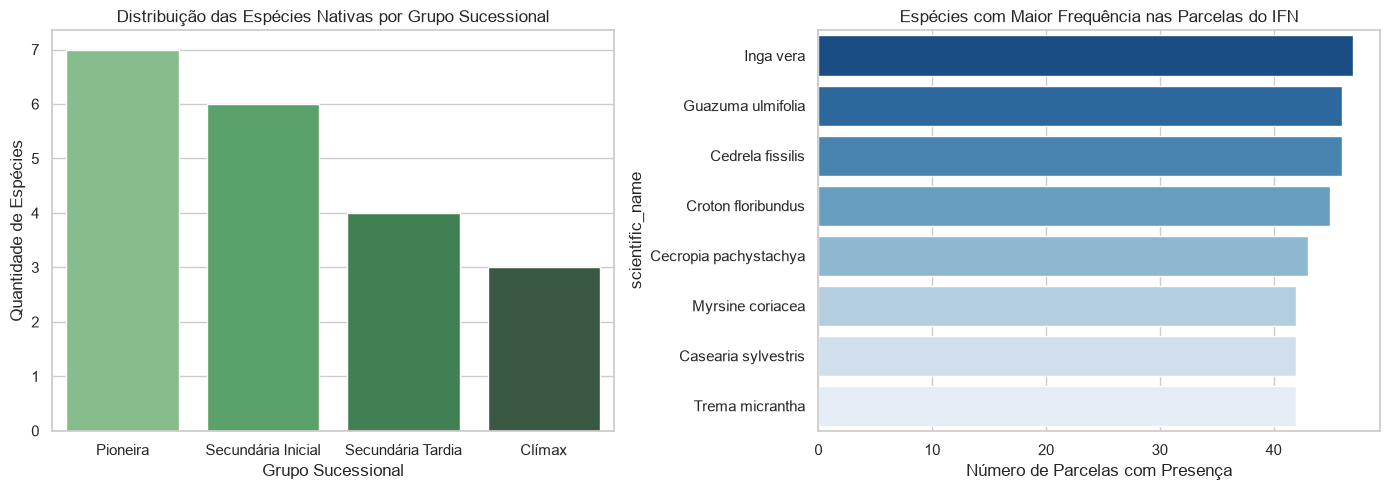

In [5]:
# 2.1 Visualização da Riqueza de Espécies e Distribuição de Sucessão
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Grupos Sucessionais
sns.countplot(data=df_flora_raw[~df_flora_raw['biome'].str.contains("Exótica")], 
              x="successional_stage", ax=axes[0], palette="Greens_d")
axes[0].set_title("Distribuição das Espécies Nativas por Grupo Sucessional")
axes[0].set_xlabel("Grupo Sucessional")
axes[0].set_ylabel("Quantidade de Espécies")

# Gráfico 2: Distribuição de Frequência nas Parcelas do IFN
top_ifn = df_ifn_raw['scientific_name'].value_counts().head(8)
sns.barplot(x=top_ifn.values, y=top_ifn.index, ax=axes[1], palette="Blues_r")
axes[1].set_title("Espécies com Maior Frequência nas Parcelas do IFN")
axes[1].set_xlabel("Número de Parcelas com Presença")

plt.tight_layout()
plt.savefig(os.path.join(DATA_PROC, 'eda_sucessao_frequencia.png'), dpi=200)
plt.show()

In [6]:
# 2.2 Cálculo da Esparsidade da Matriz Parcela x Espécie
n_plots = df_ifn_raw['plot_id'].nunique()
n_species = df_ifn_raw['scientific_name'].nunique()
n_interactions = len(df_ifn_raw)
total_possible = n_plots * n_species
sparsity = 1.0 - (n_interactions / total_possible)

print(f"=== Diagnóstico da Matriz de Interação Parcela-Espécie ===")
print(f"Total de Parcelas (Usuários u): {n_plots}")
print(f"Total de Espécies Únicas (Itens i): {n_species}")
print(f"Interações Não-Nulas Observadas (r_ui > 0): {n_interactions}")
print(f"Capacidade Total da Matriz: {total_possible}")
print(f"Taxa de Esparsidade: {sparsity * 100:.2f}% (Esparsidade Típica de Sistemas de Recomendação Reais)")

=== Diagnóstico da Matriz de Interação Parcela-Espécie ===
Total de Parcelas (Usuários u): 100
Total de Espécies Únicas (Itens i): 20
Interações Não-Nulas Observadas (r_ui > 0): 710
Capacidade Total da Matriz: 2000
Taxa de Esparsidade: 64.50% (Esparsidade Típica de Sistemas de Recomendação Reais)


## 3. Limpeza, Resolução Taxonômica e Pré-processamento
Nesta seção aplicamos os procedimentos metodológicos do grupo:
1. **Resolução de Sinonímias Taxonômicas:** Mapeamento de nomes científicos para o táxon válido aceito no JBRJ.
2. **Expurgo de Espécies Invasoras:** Eliminação de exóticas que desrespeitam o ODS 15.
3. **Subamostragem Espacial (*Spatial Thinning*):** Regularização geográfica no GBIF com grade de $0.05^\circ \approx 5.5\text{ km}$.
4. **Imputação Filogenética de Missing Values.**

In [7]:
# 3.1 Dicionário de Sinonímias e Resolução
taxa_dict = dict(zip(df_flora_raw['scientific_name'], df_flora_raw['synonym_of']))

# Remove espécies exóticas invasoras
especies_exoticas = set(df_flora_raw[df_flora_raw['biome'].str.contains("Exótica")]['scientific_name'])

# Aplica resolução na base Flora
df_flora_clean = df_flora_raw[~df_flora_raw['scientific_name'].isin(especies_exoticas)].copy()
df_flora_clean['accepted_name'] = df_flora_clean['scientific_name'].map(taxa_dict)
df_flora_clean = df_flora_clean.drop_duplicates(subset=['accepted_name']).reset_index(drop=True)

# Aplica resolução no IFN
df_ifn_clean = df_ifn_raw[~df_ifn_raw['scientific_name'].isin(especies_exoticas)].copy()
df_ifn_clean['accepted_name'] = df_ifn_clean['scientific_name'].map(taxa_dict)

# Agrega duplicatas na mesma parcela geradas por sinonímias
df_ifn_clean = df_ifn_clean.groupby(
    ['conglomerado_id', 'plot_id', 'bioma', 'latitude', 'longitude', 
     'textura_solo', 'ph_solo', 'saturacao_v_porc', 'precipitacao_anual_mm', 'drenagem_solo', 'accepted_name'],
    as_index=False
)['individuos_vivos'].sum()

print(f"Flora após resolução taxonômica: {len(df_flora_clean)} espécies aceitas únicas.")
print(f"IFN após resolução taxonômica e agregação: {len(df_ifn_clean)} registros.")

# 3.2 Spatial Thinning no GBIF
# Discretiza coordenadas em grid de 0.05 graus (~5.5 km)
df_gbif_clean = df_gbif_raw.copy()
df_gbif_clean['accepted_name'] = df_gbif_clean['scientific_name'].map(taxa_dict)
df_gbif_clean = df_gbif_clean.dropna(subset=['accepted_name'])

df_gbif_clean['grid_lat'] = (df_gbif_clean['latitude'] / 0.05).round() * 0.05
df_gbif_clean['grid_lon'] = (df_gbif_clean['longitude'] / 0.05).round() * 0.05

# Mantém apenas um registro por espécie por célula espacial
df_gbif_thinned = df_gbif_clean.drop_duplicates(subset=['accepted_name', 'grid_lat', 'grid_lon']).reset_index(drop=True)

print(f"GBIF antes do Spatial Thinning: {len(df_gbif_raw)} registros.")
print(f"GBIF após Spatial Thinning: {len(df_gbif_thinned)} registros (Redução de {100*(1 - len(df_gbif_thinned)/len(df_gbif_raw)):.1f}% do viés urbano).")

Flora após resolução taxonômica: 17 espécies aceitas únicas.
IFN após resolução taxonômica e agregação: 710 registros.
GBIF antes do Spatial Thinning: 774 registros.
GBIF após Spatial Thinning: 759 registros (Redução de 1.9% do viés urbano).


## 4. Exportação dos Dados Processados e Amostras Curadas
Exportamos os dados saneados para `data/processed/` e `data/sample/`, garantindo a integração com o módulo `src/data_prep.py`.

In [8]:
# 4.1 Exportar bases processadas completas
df_flora_clean.to_csv(os.path.join(DATA_PROC, 'flora_brasil_processed.csv'), index=False)
df_ifn_clean.to_csv(os.path.join(DATA_PROC, 'ifn_parcelas_processed.csv'), index=False)
df_gbif_thinned.to_csv(os.path.join(DATA_PROC, 'gbif_thinned_processed.csv'), index=False)

# 4.2 Exportar amostras curadas para versionamento no Git (data/sample/)
df_flora_clean.to_csv(os.path.join(DATA_SAMPLE, 'flora_brasil_sample.csv'), index=False)
df_ifn_clean.to_csv(os.path.join(DATA_SAMPLE, 'ifn_parcelas_sample.csv'), index=False)
df_gbif_thinned.to_csv(os.path.join(DATA_SAMPLE, 'gbif_occurrences_sample.csv'), index=False)

print("✓ Artefatos exportados com sucesso para data/processed/ e data/sample/!")

✓ Artefatos exportados com sucesso para data/processed/ e data/sample/!
